In [ ]:
# Paths (relative to the repository root, so the notebooks run on any machine)
# Expected layout:  <repo>/notebooks/ (this file), <repo>/data/, <repo>/models/,
#                   <repo>/figures/, <repo>/results/, <repo>/feature_importance/
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
MODELS_DIR = ROOT / "models"
FIG_DIR = ROOT / "figures"
RESULTS_DIR = ROOT / "results"
FI_DIR = ROOT / "feature_importance"
for _d in (DATA_DIR, MODELS_DIR, FIG_DIR, RESULTS_DIR, FI_DIR):
    _d.mkdir(parents=True, exist_ok=True)


## **Model Comparison and Explainable Machine Learning**

In [1]:
# Import Libraries

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from scipy.stats import zscore

import shap

from sklearn.preprocessing import StandardScaler

from sklearn.inspection import permutation_importance

from sklearn.inspection import PartialDependenceDisplay

from sklearn.inspection import (
    permutation_importance,
    PartialDependenceDisplay
)

from sklearn.model_selection import KFold, cross_validate

from sklearn.metrics import (
    r2_score,
    make_scorer,
    mean_absolute_error,
    mean_squared_error
)

In [2]:
# Load the Train/Test Data

X_train = pd.read_csv(
    str(DATA_DIR / "X_train1.csv")
)

X_test = pd.read_csv(
    str(DATA_DIR / "X_test1.csv")
)

y_train = pd.read_csv(
    str(DATA_DIR / "y_train1.csv")
).squeeze("columns")

y_test = pd.read_csv(
    str(DATA_DIR / "y_test1.csv")
).squeeze("columns")

In [3]:
# Load the Best Model

best_model = joblib.load(
    str(MODELS_DIR / "Best_CatBoost_Model1.pkl")
)

# Verify the Model

print(best_model)

CatBoostRegressor(bagging_temperature=1, depth=10, iterations=1000, l2_leaf_reg=1, learning_rate=0.1, loss_function='RMSE', random_state=42, random_strength=1, verbose=0)


In [4]:
# Creating the Model comparison table

# Read all tables

rf = pd.read_csv(str(RESULTS_DIR / "RandomForest_Performance_Table1.csv"))
xgb = pd.read_csv(str(RESULTS_DIR / "XGBoost_Performance_Table1.csv"))
cat = pd.read_csv(str(RESULTS_DIR / "CatBoost_Performance_Table1.csv"))
lgb = pd.read_csv(str(RESULTS_DIR / "LightGBM_Performance_Table1.csv"))

# Add model names
rf["Model"] = "Random Forest"
xgb["Model"] = "XGBoost"
cat["Model"] = "CatBoost"
lgb["Model"] = "LightGBM"

# Merge them
comparison = pd.concat(
    [rf, xgb, cat, lgb],
    ignore_index=True
)

In [5]:
comparison = comparison[
    [
        "Model",
        "Dataset",
        "R²",
        "RMSE",
        "MAE",
        "Pearson r",
        "Spearman ρ",
    ]
]

# Round values
comparison = comparison.round(4)

comparison

,Model,Dataset,R²,RMSE,MAE,Pearson r,Spearman ρ
0,Random Forest,Training,0.9426,0.1926,0.1340,0.9727,0.9725
1,Random Forest,Testing,0.7748,0.3721,0.2586,0.8805,0.8765
2,XGBoost,Training,0.9196,0.2280,0.1646,0.9616,0.9596
3,XGBoost,Testing,0.7925,0.3572,0.2575,0.8916,0.8872
4,CatBoost,Training,0.9450,0.1885,0.1377,0.9736,0.9715
5,CatBoost,Testing,0.8031,0.3479,0.2510,0.8970,0.8926
6,LightGBM,Training,0.9354,0.2044,0.1398,0.9682,0.9667
7,LightGBM,Testing,0.8011,0.3496,0.2486,0.8954,0.8913


In [6]:
# Save the comparison table

comparison.to_csv(
    str(RESULTS_DIR / "Model_Comparison_Table1.csv"),
    index=False
)

## **5Fold_CrossValidation**

In [7]:
# Load the datasets

X_train = pd.read_csv(str(DATA_DIR / "X_train1.csv"))
y_train = pd.read_csv(str(DATA_DIR / "y_train1.csv")).squeeze()

print(X_train.shape)
print(y_train.shape)

(21440, 1442)
(21440,)


In [8]:
# Define the CV strategy

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [9]:
# Define RMSE scorer
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

rmse_scorer = make_scorer(
    rmse,
    greater_is_better=False
)

In [10]:
# Define all scoring metrics
scoring = {
    "R2": "r2",
    "RMSE": rmse_scorer,
    "MAE": "neg_mean_absolute_error"
}

In [15]:
# Create ONE reusable function

def evaluate_cv(model_path, model_name):

    model = joblib.load(model_path)

    cv_results = cross_validate(
        estimator=model,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    # Calculate mean and standard deviation
    cv_r2_mean = cv_results["test_R2"].mean()
    cv_r2_std = cv_results["test_R2"].std()

    cv_rmse_mean = -cv_results["test_RMSE"].mean()
    cv_rmse_std = cv_results["test_RMSE"].std()

    cv_mae_mean = -cv_results["test_MAE"].mean()
    cv_mae_std = cv_results["test_MAE"].std()

    results = {
        "Model": model_name,

        # Numeric values — useful for plotting
        "CV_R2_mean": cv_r2_mean,
        "CV_R2_std": cv_r2_std,

        # Formatted values — useful for manuscript table
        "CV R²": f"{cv_r2_mean:.4f} ± {cv_r2_std:.4f}",
        "CV RMSE": f"{cv_rmse_mean:.4f} ± {cv_rmse_std:.4f}",
        "CV MAE": f"{cv_mae_mean:.4f} ± {cv_mae_std:.4f}"
    }

    return results

In [16]:
# Evaluate every model

rf = evaluate_cv(     
    str(MODELS_DIR / "Best_RandomForest_Model1.pkl"),
    "Random Forest"
)

xgb = evaluate_cv(
    str(MODELS_DIR / "Best_XGBoost_Model1.pkl"),
    "XGBoost"
)

cat = evaluate_cv(
    str(MODELS_DIR / "Best_CatBoost_Model1.pkl"),
    "CatBoost"
)

lgb = evaluate_cv(
    str(MODELS_DIR / "Best_LightGBM_Model1.pkl"),
    "LightGBM"
)

In [17]:
# Make the manuscript table
cv_table = pd.DataFrame([
    rf,
    xgb,
    cat,
    lgb
])

# Columns to display in manuscript
cv_table_manuscript = cv_table[
    ["Model", "CV R²", "CV RMSE", "CV MAE"]
]

cv_table_manuscript

,Model,CV R²,CV RMSE,CV MAE
0,Random Forest,0.7485 ± 0.0089,0.4031 ± 0.0085,0.2818 ± 0.0055
1,XGBoost,0.7784 ± 0.0056,0.3785 ± 0.0072,0.2719 ± 0.0047
2,CatBoost,0.7833 ± 0.0073,0.3742 ± 0.0082,0.2677 ± 0.0042
3,LightGBM,0.7845 ± 0.0055,0.3733 ± 0.0069,0.2651 ± 0.0044


In [18]:
# Save the Crossvalidation table
cv_table.to_csv(
    str(RESULTS_DIR / "CrossValidation_Table1.csv"),
    index=False
)

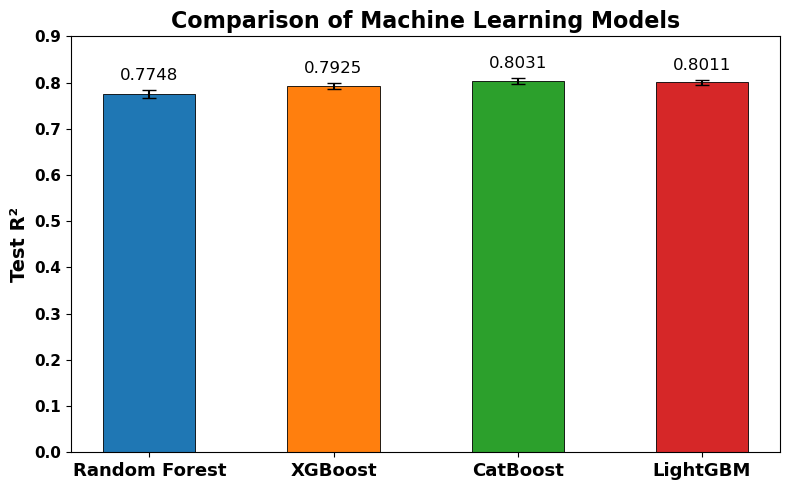

In [19]:
# Plot the Comparison

# Different colors for each model
colors = ["#1F77B4", "#FF7F0E", "#2CA02C", "#D62728"]

# Automatically retrieve CV R² standard deviations
cv_r2_std = cv_table["CV_R2_std"].to_numpy()

# Testing R² values
test_data = comparison.loc[
    comparison["Dataset"] == "Testing"
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    test_data["Model"],
    test_data["R²"],
    yerr=cv_r2_std,
    capsize=5,
    color=colors,
    width=0.5,
    edgecolor="black",
    linewidth=0.6
)

plt.ylabel(
    "Test R²",
    fontsize=14,
    fontweight="bold"
)

plt.title(
    "Comparison of Machine Learning Models",
    fontsize=16,
    fontweight="bold"
)

plt.xticks(
    fontsize=13,
    fontweight="bold"
)

plt.yticks(
    fontsize=11,
    fontweight="bold"
)

plt.ylim(0, 0.9)

# Add R² values above error bars
for bar, err in zip(bars, cv_r2_std):

    r2_value = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        r2_value + err + 0.015,
        f"{r2_value:.4f}",
        ha="center",
        va="bottom",
        fontsize=12
    )

plt.tight_layout()

# Save figure
plt.savefig(
    str(FIG_DIR / "Model_Comparison_R2_1.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

## **Model Interpretation**

## **SHAP Explainability**

In [8]:
# Create the SHAP Explainer

explainer = shap.TreeExplainer(best_model)

# Calculate the SHAP Values

shap_values = explainer.shap_values(X_test)

In [6]:
# Verify the output

print(type(shap_values))
print(np.array(shap_values).shape)

<class 'numpy.ndarray'>
(5361, 1442)


In [9]:
mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_SHAP": mean_abs_shap
}).sort_values("Mean_SHAP", ascending=False).reset_index(drop=True)

shap_importance_df.to_csv(
    str(FI_DIR / "SHAP_Importance_1.csv"),   
    index=False
)

print(shap_values.shape, len(X_test.columns))

print(shap_importance_df.head(20))

(5361, 1442) 1442
                   Feature  Mean_SHAP
0                  MolLogP   0.044815
1           Charge_complex   0.033965
2             FilterItLogS   0.033960
3                PEOE_VSA5   0.032319
4              fr_pyridine   0.026420
5   NumAromaticCarbocycles   0.026294
6                  AATSC0c   0.023479
7            Atomic_number   0.023194
8                    piPC9   0.021736
9                NHOHCount   0.019482
10              PEOE_VSA10   0.018538
11                   nAcid   0.018459
12                Metal_Ru   0.016551
13              NumHDonors   0.014954
14                 n6HRing   0.014844
15               PEOE_VSA1   0.014178
16         Cell_line_A2780   0.013389
17               PEOE_VSA6   0.013229
18                 AATSC1i   0.012055
19                 AATSC0v   0.011450


## **SHAP Summary (Beeswarm) Plot**

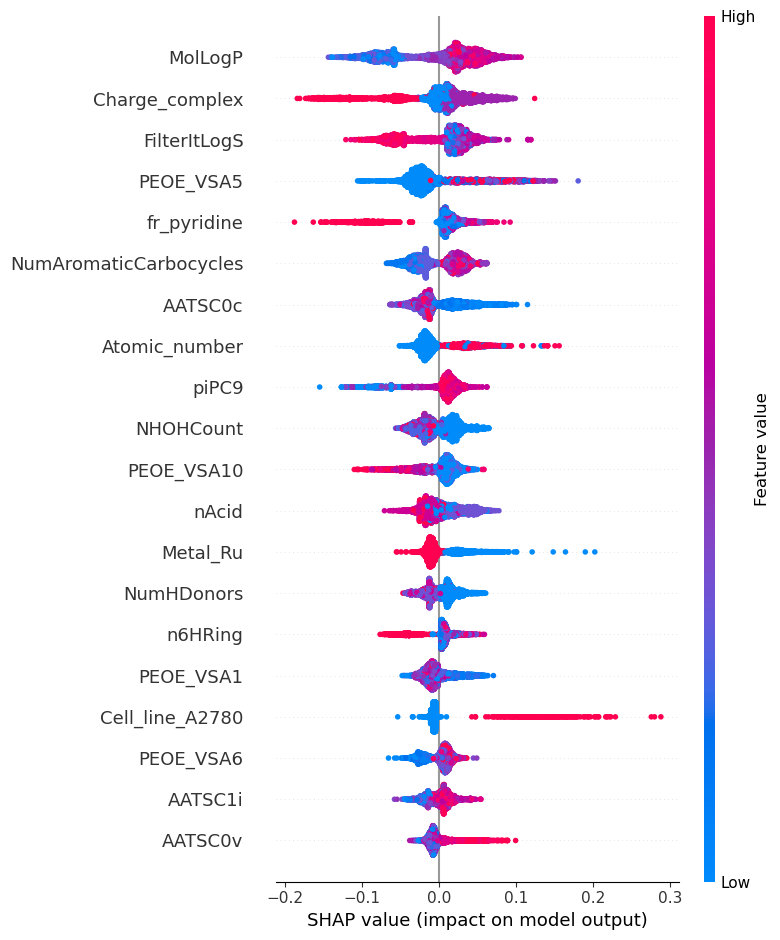

In [7]:
shap.summary_plot(
    shap_values,
    X_test,
    max_display=20,
    show=False
)

plt.tight_layout()

# Save the Beeswarm Plot

plt.savefig(
    str(FIG_DIR / "SHAP_Beeswarm_1.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## **SHAP Bar Plot**

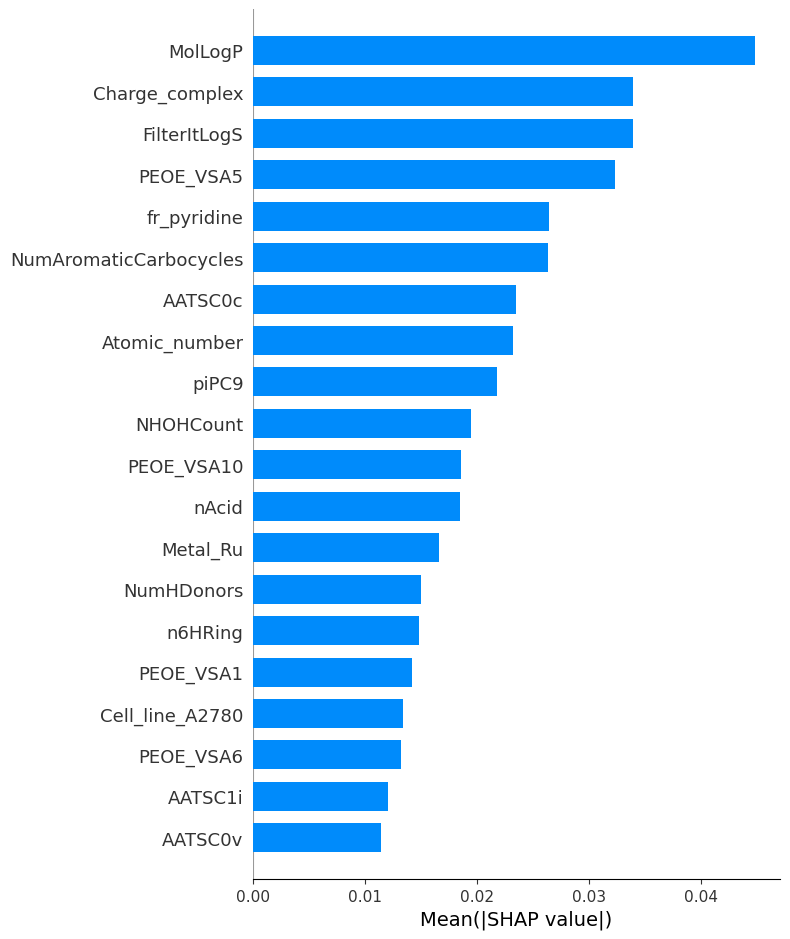

In [8]:
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.xlabel(
    "Mean(|SHAP value|)",
    fontsize=14
)

plt.tight_layout()

# Save the Bar Plot

plt.savefig(
    str(FIG_DIR / "SHAP_Bar_1.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## **Permutation Importance**

In [20]:
# Calculate permutation importance

perm_importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="r2",
    n_jobs=-1
)

In [21]:
# Create a DataFrame

perm_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": perm_importance.importances_mean,
    "Std": perm_importance.importances_std
})

In [22]:
# Sort the features

perm_df = perm_df.sort_values(
    by="Importance",
    ascending=False
)

In [23]:
# View the top features

perm_df.head(20)

,Feature,Importance,Std
106,MolLogP,0.030722,0.001693
0,Charge_complex,0.023992,0.001437
39,PEOE_VSA5,0.018456,0.001288
613,FilterItLogS,0.015940,0.001175
166,fr_pyridine,0.012884,0.000884
958,Cell_line_HEK293,0.011530,0.000604
619,piPC9,0.011185,0.000662
972,Cell_line_HL-7702,0.009437,0.000399
178,nAcid,0.008621,0.000814
313,AATSC0c,0.008202,0.000831


In [24]:
# Save the results

perm_df.to_csv(
    str(FI_DIR / "Permutation_Importance_1.csv"),
    index=False
)

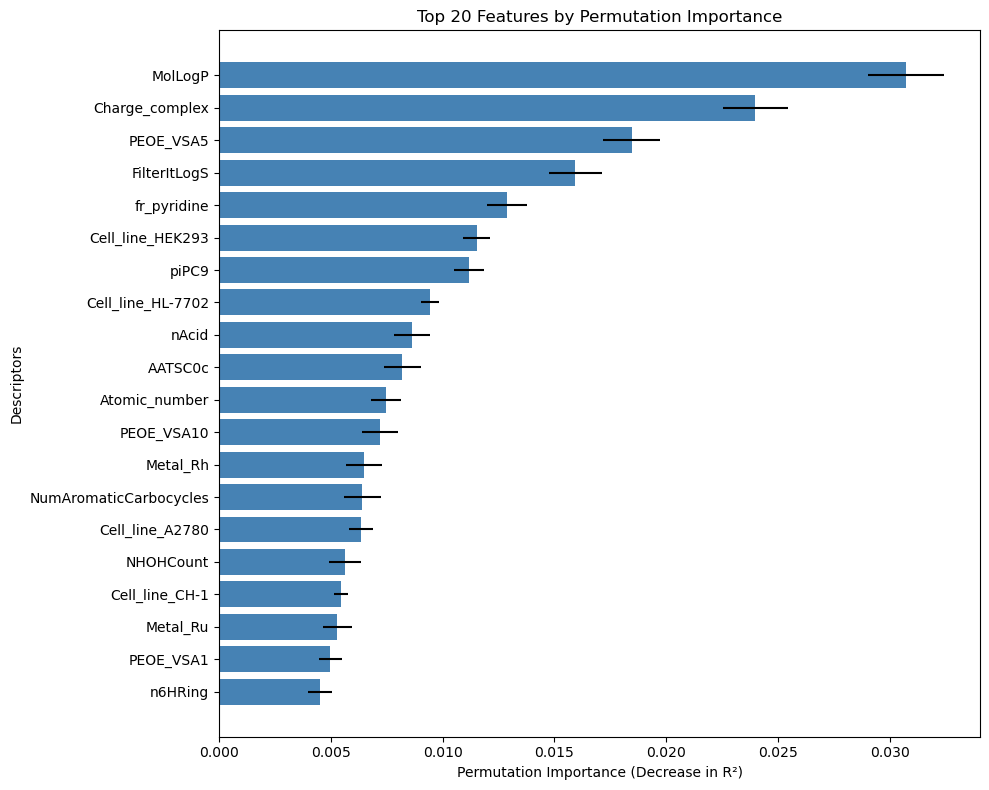

In [25]:
# Plot the Permutation Importance

# Top 20 features
top20 = perm_df.head(20)

plt.figure(figsize=(10,8))

plt.barh(
    top20["Feature"][::-1],
    top20["Importance"][::-1],
    xerr=top20["Std"][::-1],
    color="steelblue"
)

plt.xlabel("Permutation Importance (Decrease in R²)")
plt.ylabel("Descriptors")
plt.title("Top 20 Features by Permutation Importance")

plt.tight_layout()

plt.savefig(
    str(FIG_DIR / "Permutation_Importance_1.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

## **Partial Dependence Plots (PDP) and Individual Conditional Expectation (ICE)**

In [4]:
# Define the descriptors

top_features = [
    "MolLogP",
    "Charge_complex",
    "PEOE_VSA5",
    "FilterItLogS",
    "fr_pyridine",
    "AATSC0c",
    "NHOHCount",
    "Atomic_number",
    "PEOE_VSA10",
    "NumAromaticCarbocycles"
]

In [5]:
# Check which columns are integers

X_train.dtypes.value_counts()

# Convert ALL columns to float

X_train = X_train.astype(np.float64)
X_test = X_test.astype(np.float64)


# verify

X_train.dtypes.unique()

array([dtype('float64')], dtype=object)

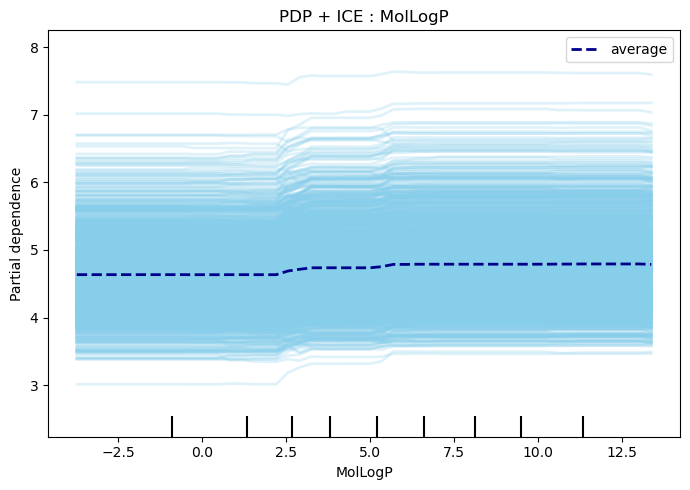

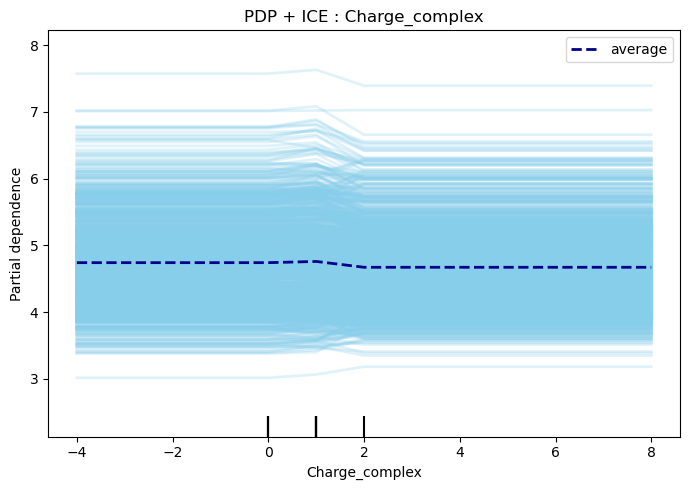

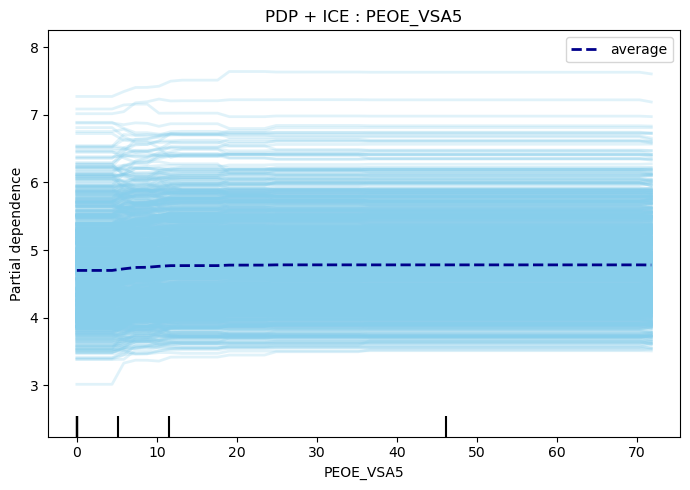

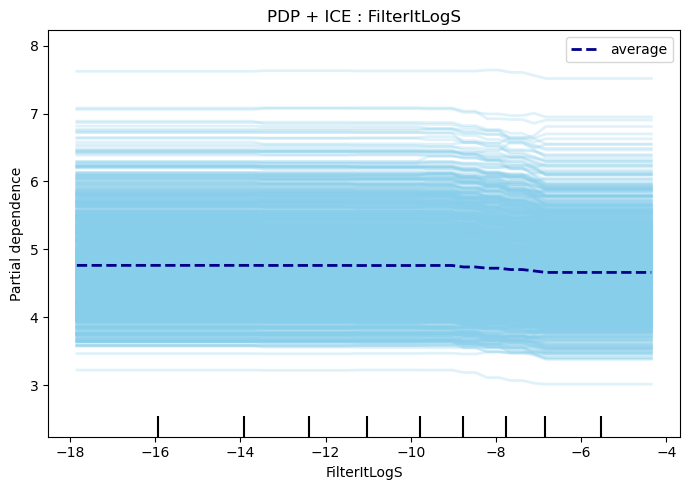

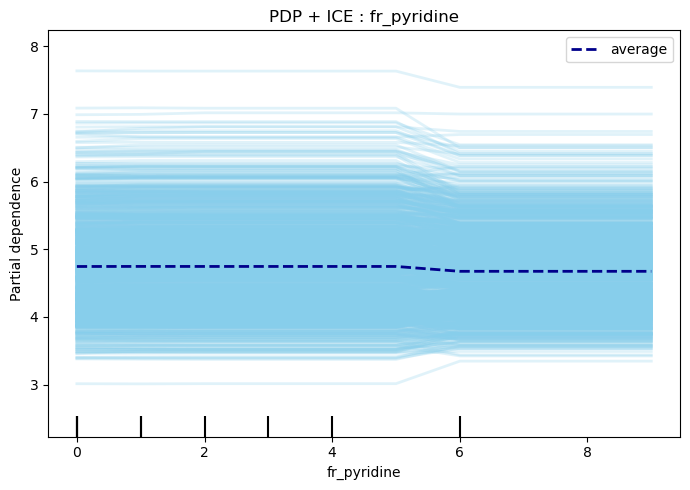

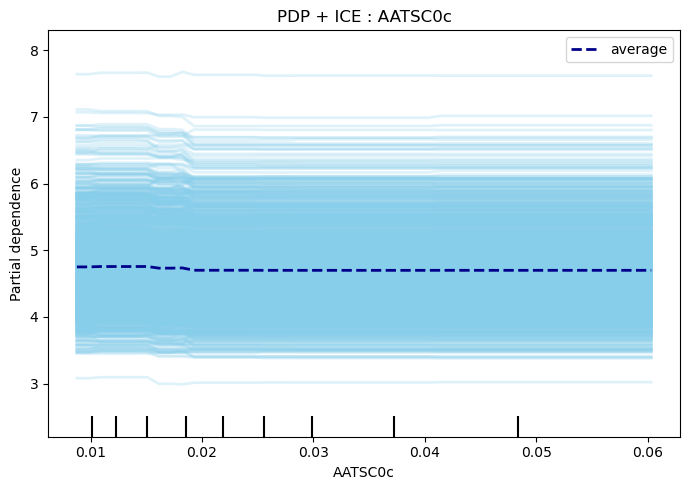

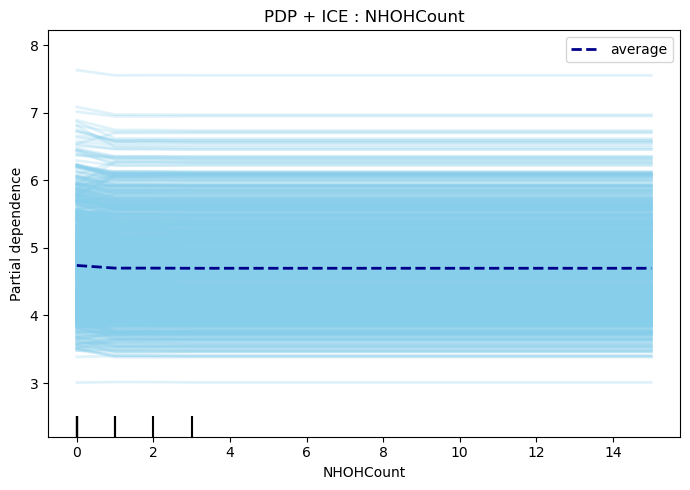

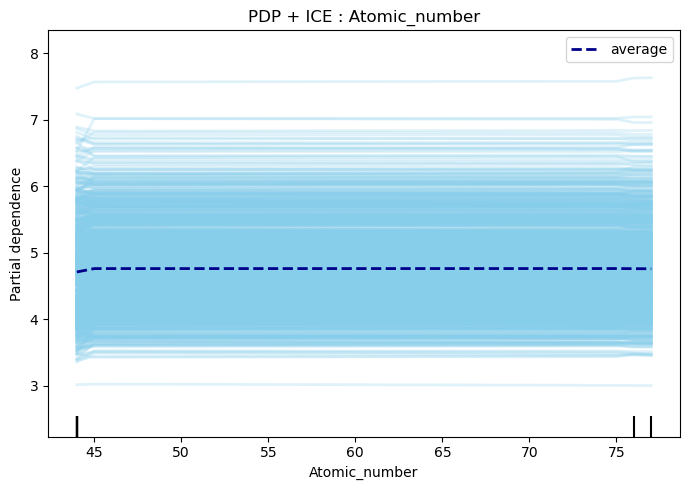

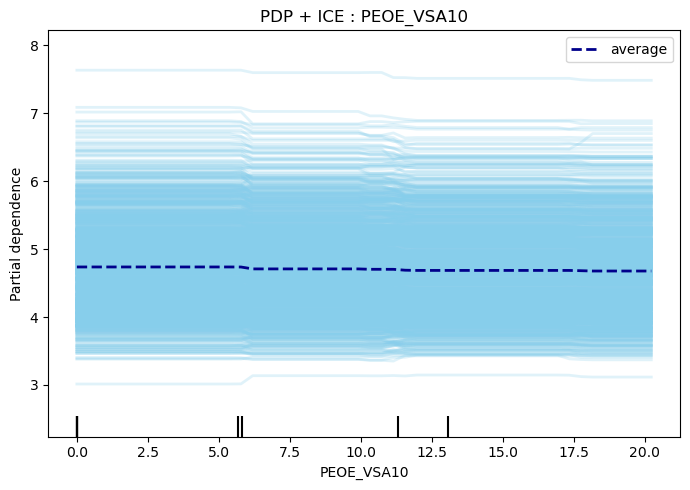

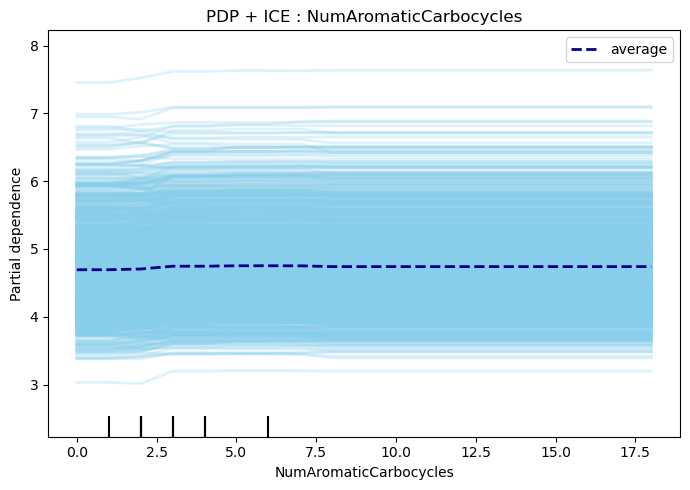

In [6]:
# Generate PDP+ICE Plot

for feature in top_features:

    fig, ax = plt.subplots(figsize=(7,5))

    PartialDependenceDisplay.from_estimator(
        estimator=best_model,
        X=X_train,
        features=[feature],
        kind="both",          # PDP + ICE
        subsample=1000,        # Draw ICE curves for 1000 samples
        random_state=42,
        line_kw={"color": "darkblue", "linewidth": 2},          # PDP line
        ice_lines_kw={"color": "skyblue", "alpha": 0.25}, # ICE lines
        grid_resolution=50,
        ax=ax
    )

    plt.title(f"PDP + ICE : {feature}")

    plt.tight_layout()

    plt.savefig(
        str(FIG_DIR / f"1_PDP_{feature}.png"),
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()

## **SHAP Dependence Plot**

<Figure size 800x600 with 0 Axes>

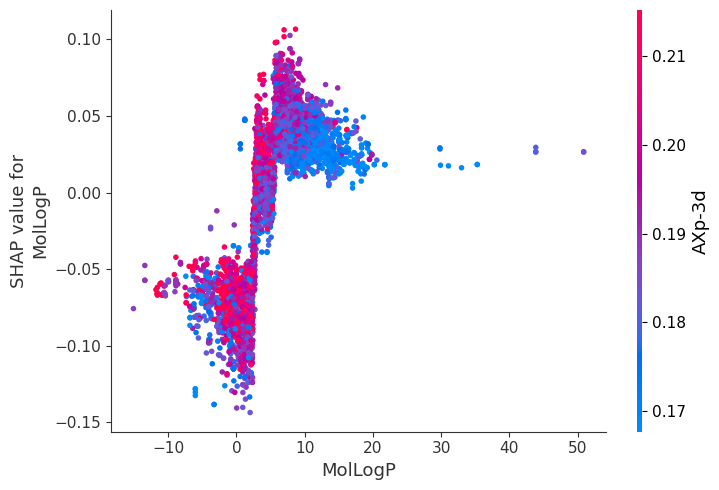

<Figure size 800x600 with 0 Axes>

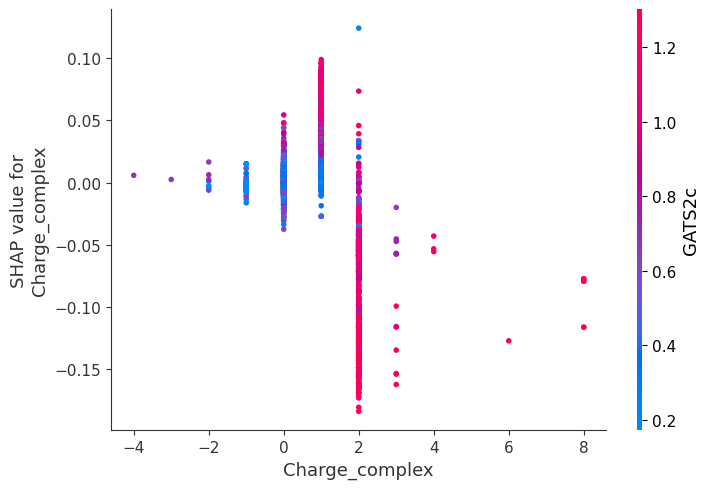

<Figure size 800x600 with 0 Axes>

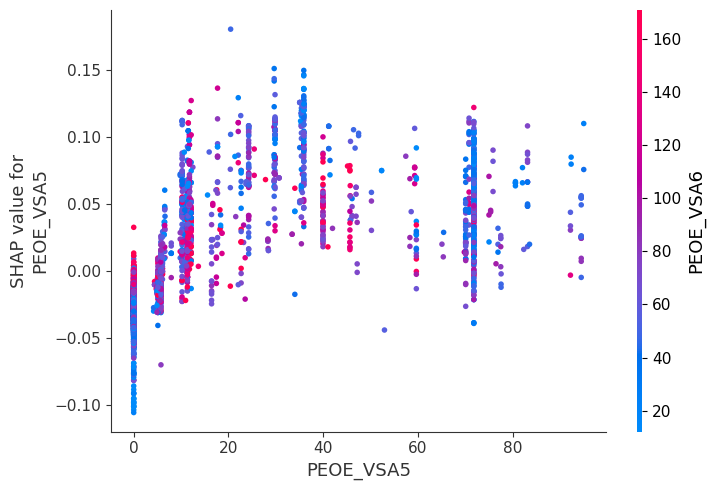

<Figure size 800x600 with 0 Axes>

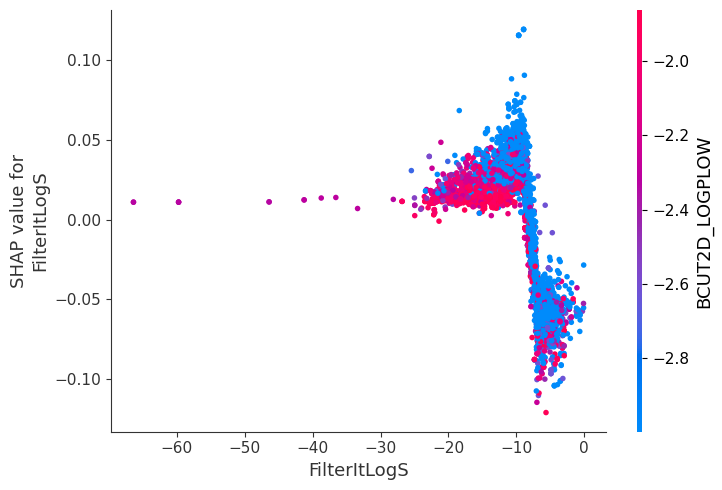

<Figure size 800x600 with 0 Axes>

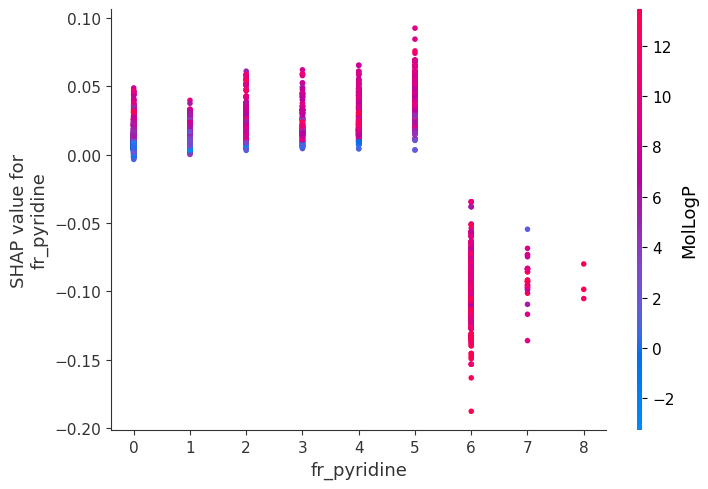

<Figure size 800x600 with 0 Axes>

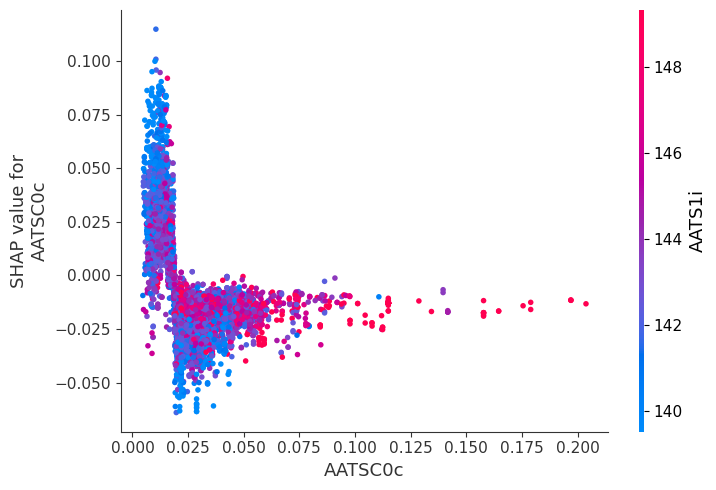

<Figure size 800x600 with 0 Axes>

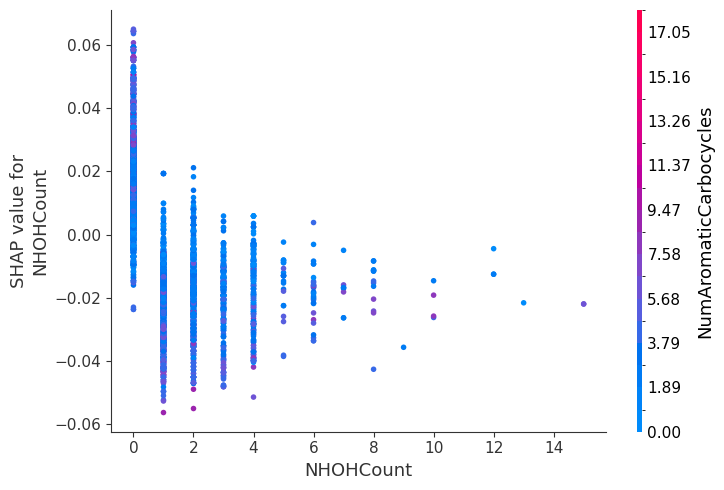

<Figure size 800x600 with 0 Axes>

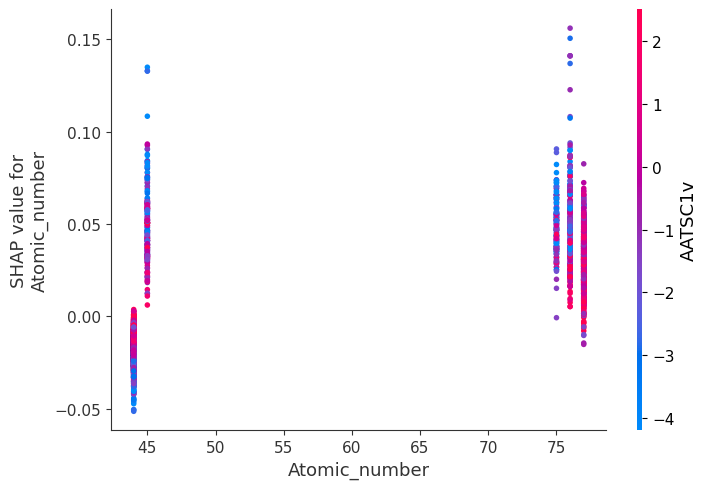

<Figure size 800x600 with 0 Axes>

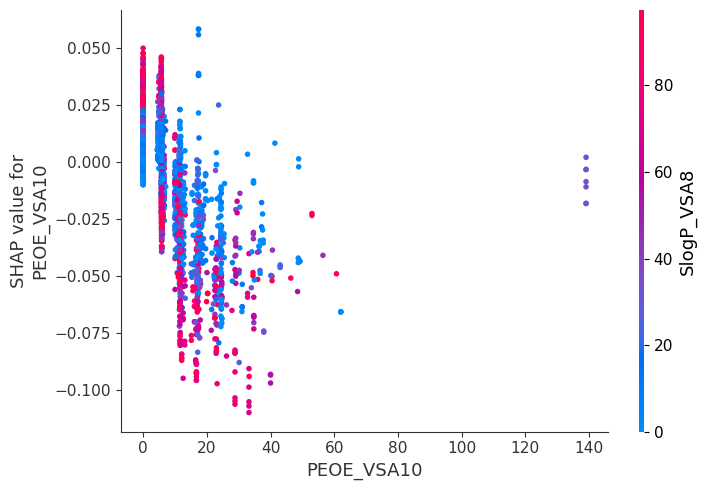

<Figure size 800x600 with 0 Axes>

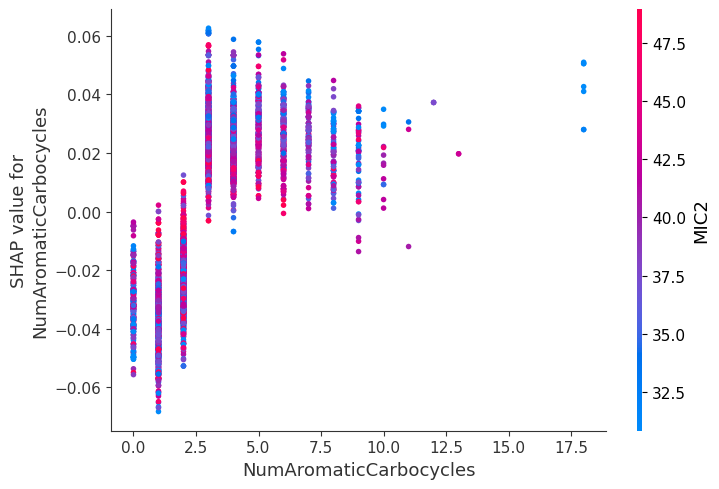

In [9]:
# Define the descriptors

top_features = [
    "MolLogP",
    "Charge_complex",
    "PEOE_VSA5",
    "FilterItLogS",
    "fr_pyridine",
    "AATSC0c",
    "NHOHCount",
    "Atomic_number",
    "PEOE_VSA10",
    "NumAromaticCarbocycles"
]

for feature in top_features:

    plt.figure(figsize=(8,6))

    shap.dependence_plot(
        feature,
        shap_values,
        X_test,          # <-- Use X_test
        interaction_index="auto",
        show=False
    )

    plt.tight_layout()

    plt.savefig(
        str(FIG_DIR / f"1_SHAP_Dependence_{feature}.png"),
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()

In [30]:
print(shap_values.shape)
print(X_train.shape)
print(X_test.shape)

(5361, 1442)
(21440, 1442)
(5361, 1442)


## **Model Validation and Visualization**

### **Scatter Plot**

In [4]:
# Create the observed vs predicted Scatter Plot (Training)

# Generate predictions

# Since your best model is Optimized CatBoost

train_pred = best_model.predict(X_train)
test_pred = best_model.predict(X_test)

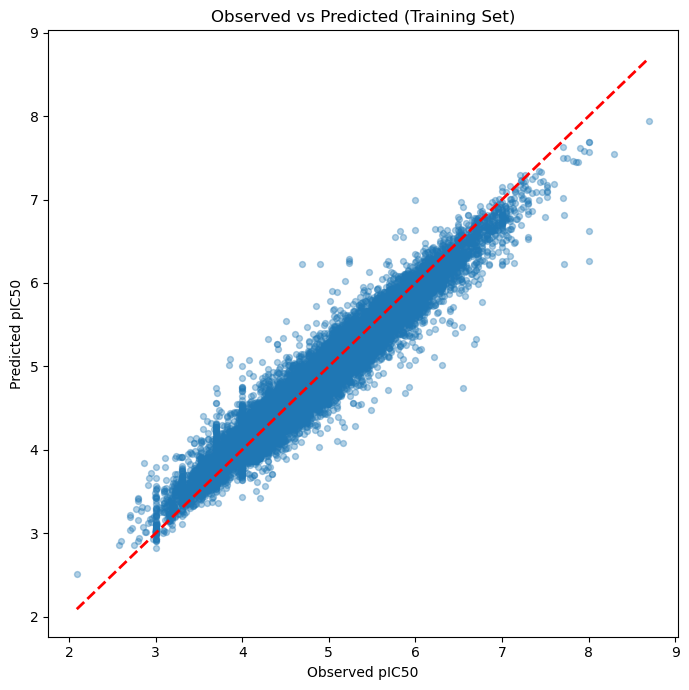

In [32]:
# Plot the Training Scatter Plot

plt.figure(figsize=(7,7))

plt.scatter(
    y_train,
    train_pred,
    s=18,
    alpha=0.35
)
plt.plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    'r--',
    linewidth=2
)

plt.xlabel("Observed pIC50")
plt.ylabel("Predicted pIC50")
plt.title("Observed vs Predicted (Training Set)")

plt.tight_layout()

# Save the scatter plot of training

plt.savefig(
    str(FIG_DIR / "Observed_vs_Predicted_Training_1.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

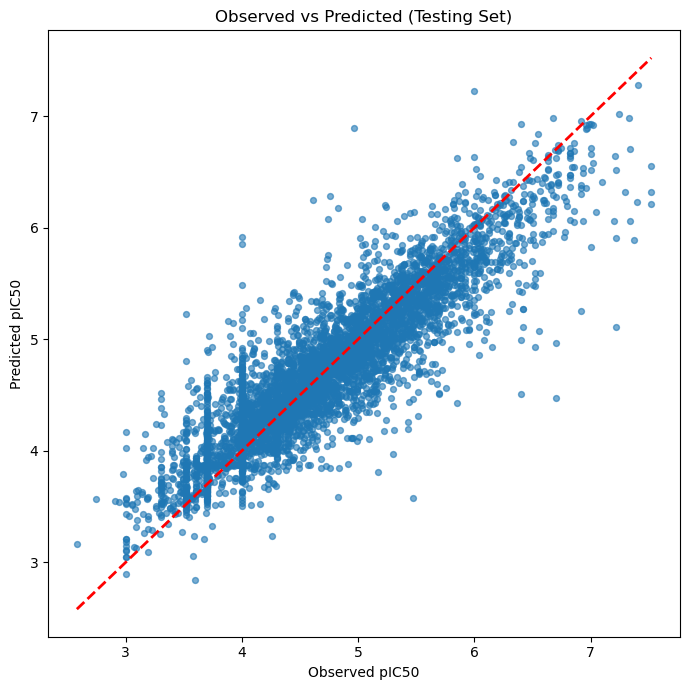

In [33]:
# Create the observed vs predicted Scatter Plot (Testing)

plt.figure(figsize=(7,7))

plt.scatter(
    y_test,
    test_pred,
    s=18,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    linewidth=2
)

plt.xlabel("Observed pIC50")
plt.ylabel("Predicted pIC50")
plt.title("Observed vs Predicted (Testing Set)")

plt.tight_layout()

plt.savefig(
    str(FIG_DIR / "Observed_vs_Predicted_Testing_1.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### **Residual Analysis**

In [34]:
# Calculate the residuals

train_residuals = y_train - train_pred
test_residuals = y_test - test_pred

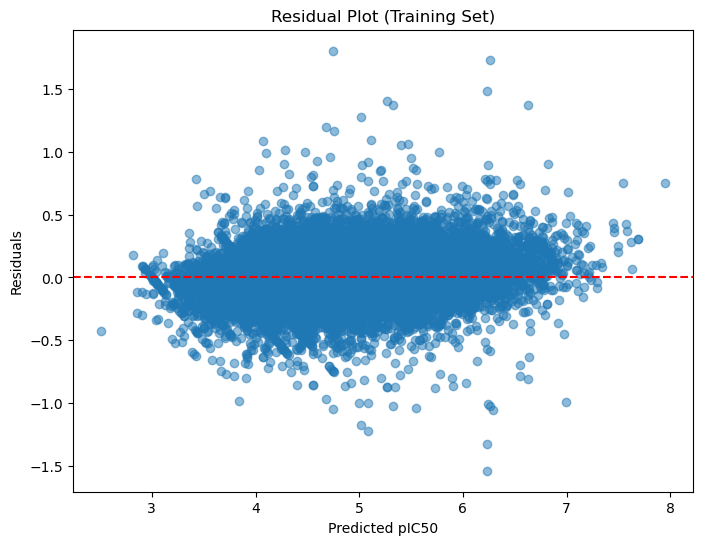

In [35]:
# Plot the residuals analysis for Training set

plt.figure(figsize=(8,6))

plt.scatter(
    train_pred,
    train_residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted pIC50")
plt.ylabel("Residuals")
plt.title("Residual Plot (Training Set)")

plt.savefig(
    str(FIG_DIR / "Training_Residual_Plot_1.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

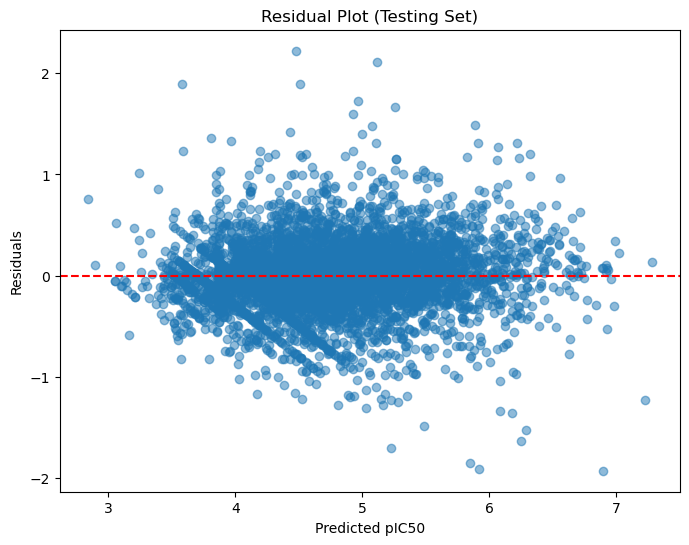

In [36]:
# Plot the residuals analysis for the testing set

plt.figure(figsize=(8,6))

plt.scatter(
    test_pred,
    test_residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted pIC50")
plt.ylabel("Residuals")
plt.title("Residual Plot (Testing Set)")

plt.savefig(
    str(FIG_DIR / "Testing_Residual_Plot_1.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## **Applicability Domain (Williams Plot)**

In [5]:
# Recomputing the williams plot using molecular descriptors only 

# Create a copy of your training data
X_train_AD = X_train.copy()

In [6]:
#Remove all one-hot encoded columns

cols_to_remove = [col for col in X_train_AD.columns
                  if col.startswith("Metal_") or col.startswith("Cell_line_")]

X_train_AD = X_train_AD.drop(columns=cols_to_remove)

In [7]:
print(X_train_AD.shape)

(21440, 685)


In [8]:
# Convert all columns to float64
X_AD = X_train_AD.astype(np.float64)

print(X_AD.dtypes.unique())

[dtype('float64')]


In [9]:
# Standardized the descriptors

scaler = StandardScaler()

X_AD_scaled = scaler.fit_transform(X_AD)

print(X_AD_scaled.shape)
print(X_AD_scaled.dtype)

(21440, 685)
float64


In [10]:
# Compute the SVD method

U, S, Vt = np.linalg.svd(
    X_AD_scaled,
    full_matrices=False
)

In [11]:
print(U.shape)
print(S.shape)
print(Vt.shape)

(21440, 685)
(685,)
(685, 685)


In [12]:
# Compute leverage values

leverage = np.sum(U**2, axis=1)

print("Shape:", leverage.shape)
print("Minimum:", leverage.min())
print("Maximum:", leverage.max())


Shape: (21440,)
Minimum: 0.002791655282702632
Maximum: 0.9999563331436051


In [13]:
# Verify the leverage values

rank = np.linalg.matrix_rank(X_AD_scaled)

print("Sum of leverage:", leverage.sum())
print("Rank:", rank)

Sum of leverage: 684.9999999999999
Rank: 662


In [14]:
rank = np.linalg.matrix_rank(X_AD_scaled)

# Use only the independent left singular vectors
U_rank = U[:, :rank]

leverage = np.sum(U_rank**2, axis=1)

print("Shape:", leverage.shape)
print("Minimum:", leverage.min())
print("Maximum:", leverage.max())
print("Sum of leverage:", leverage.sum())
print("Rank:", rank)

Shape: (21440,)
Minimum: 0.002729398043599949
Maximum: 0.9999533582089566
Sum of leverage: 661.9999999999999
Rank: 662


In [15]:
# Count leverage > 0.99
print(np.sum(leverage > 0.99))

5


In [16]:
# Count near-zero variance descriptors

from sklearn.feature_selection import VarianceThreshold

selector = VarianceThreshold(threshold=1e-8)
selector.fit(X_AD)

print("Original descriptors:", X_AD.shape[1])
print("Descriptors kept:", selector.get_support().sum())

Original descriptors: 685
Descriptors kept: 685


In [17]:
# Look at the smallest singular values

print(S[-20:])

[3.02016943e-13 2.80035964e-13 2.47265007e-13 2.39781699e-13
 2.18265269e-13 1.90342530e-13 1.46741660e-13 1.42311495e-13
 1.40795587e-13 1.36612368e-13 1.21104810e-13 1.19012597e-13
 1.10505027e-13 1.10041323e-13 1.05725836e-13 1.05422896e-13
 1.02231372e-13 9.88370222e-14 9.61846642e-14 7.62441051e-14]


In [22]:
# to identify which four compounds are high leverage.

high_idx = np.where(leverage > 0.99)[0]

print(high_idx)

X_train.iloc[high_idx]

[ 6581 10231 10332 10962 16583]


,Charge_complex,Oxidation_state,Atomic_number,Valence_e,MaxAbsEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,...,Cell_line_WM1366,Cell_line_WRL68,Cell_line_WSU-DLCL2,Cell_line_WSU-NHL,Cell_line_WiDr,Cell_line_ZR-75-1,Cell_line_ZR-75-30,Cell_line_cmt167,Cell_line_fR2,Cell_line_huH-1
6581,1,2,44,8,11.238844,0.0,-0.677197,0.040103,10.500000,1097.570,...,False,False,False,False,False,False,False,False,False,False
10231,0,3,44,8,11.888339,0.0,-0.137465,0.208227,11.878788,499.805,...,False,False,False,False,False,False,False,False,False,False
10332,1,2,44,8,4.902778,0.0,0.000000,0.744705,12.476190,303.857,...,False,False,False,False,False,False,False,False,False,False
10962,1,2,44,8,9.555556,0.0,-0.611111,0.508706,7.941176,329.961,...,False,False,False,False,False,False,False,False,False,False
16583,1,3,77,9,13.261388,0.0,-0.565223,0.126093,11.250000,659.230,...,False,False,False,False,False,False,False,False,False,False


In [23]:
# let's inspect those four compounds to understand why they are extreme.

# Look at the descriptor values
X_AD.iloc[high_idx]

,Charge_complex,Oxidation_state,Atomic_number,Valence_e,MaxAbsEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,...,JGI5,JGI6,JGI7,JGI8,JGI9,JGI10,JGT10,SRW05,TSRW10,WPath
6581,1.0,2.0,44.0,8.0,11.238844,0.0,-0.677197,0.040103,10.500000,1097.570,...,0.023977,0.009759,0.009889,0.010308,0.003975,0.004302,0.329631,0.000000,115.435125,1.464000e+11
10231,0.0,3.0,44.0,8.0,11.888339,0.0,-0.137465,0.208227,11.878788,499.805,...,0.029595,0.011431,0.004721,0.007040,0.005973,0.005966,0.326997,3.713572,87.187740,9.300003e+09
10332,1.0,2.0,44.0,8.0,4.902778,0.0,0.000000,0.744705,12.476190,303.857,...,0.021465,0.000000,0.000000,0.000000,0.000000,0.000000,0.286183,0.000000,53.593943,8.400000e+09
10962,1.0,2.0,44.0,8.0,9.555556,0.0,-0.611111,0.508706,7.941176,329.961,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.436869,0.000000,43.552358,1.120000e+10
16583,1.0,3.0,77.0,9.0,13.261388,0.0,-0.565223,0.126093,11.250000,659.230,...,0.024904,0.012341,0.010417,0.006673,0.006465,0.006612,0.403878,2.397895,100.333605,4.170001e+10


In [24]:
# Calculate the standardized residuals (using the final Catboost model)

# Residuals
residuals = y_train - train_pred

# Standardized residuals
std_residuals = zscore(residuals)

print(std_residuals.shape)
print(std_residuals.min())
print(std_residuals.max())

(21440,)
-8.172665286482703
9.586769414081173


In [25]:
# Calculate the warning leverage

n = X_AD_scaled.shape[0]
rank = np.linalg.matrix_rank(X_AD_scaled)

h_star = 3 * (rank + 1) / n

print(f"Matrix Rank : {rank:.4f}")

print(f"Warning leverage (h*): {h_star:.4f}")

Matrix Rank : 662.0000
Warning leverage (h*): 0.0928


In [26]:
# Count the outliers using the corrected X_AD file.

# Normal compounds
normal = (leverage <= h_star) & (np.abs(std_residuals) <= 3)

# Structural outliers
structural = (leverage > h_star) & (np.abs(std_residuals) <= 3)

# Response outliers
response = (leverage <= h_star) & (np.abs(std_residuals) > 3)

# Both
both = (leverage > h_star) & (np.abs(std_residuals) > 3)

# Count compounds

total_compounds = len(leverage)

inside_ad = np.sum(normal)

structural_outliers = np.sum(structural)

response_outliers = np.sum(response)

both_outliers = np.sum(both)

print('Total Compounds     :', total_compounds)
print('Inside AD           :', inside_ad)
print("Structural outliers :", structural_outliers)
print("Response outliers   :", response_outliers)
print("Both                :", both_outliers)

Total Compounds     : 21440
Inside AD           : 20102
Structural outliers : 1097
Response outliers   : 236
Both                : 5


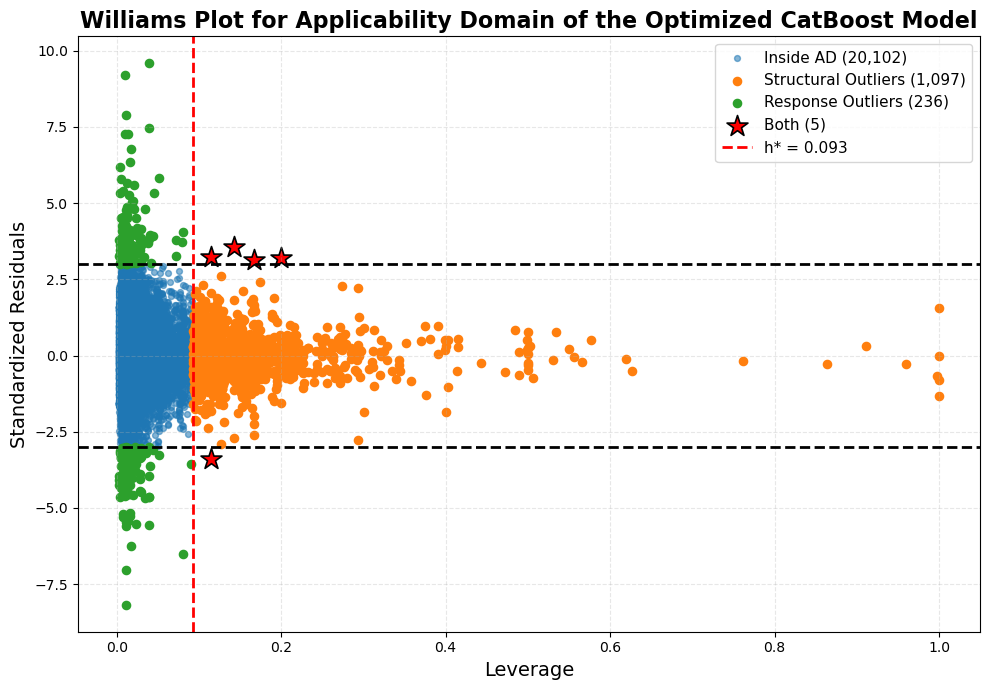

In [27]:
# Create the Williams Plot.

plt.figure(figsize=(10,7))

# Plot points

plt.scatter(
    leverage[normal],
    std_residuals[normal],
    s=18,
    alpha=0.55,
    label=f"Inside AD ({inside_ad:,})"
)

plt.scatter(
    leverage[structural],
    std_residuals[structural],
    s=35,
    label=f"Structural Outliers ({structural_outliers:,})"
)

plt.scatter(
    leverage[response],
    std_residuals[response],
    s=35,
    label=f"Response Outliers ({response_outliers:,})"
)

plt.scatter(
    leverage[both],
    std_residuals[both],
    marker="*",
    s=250,
    color="red",
    edgecolor="black",
    linewidth=1.2,
    label=f"Both ({both_outliers:,})"
)

# Threshold lines

plt.axvline(
    h_star,
    linestyle="--",
    color="red",
    linewidth=2,
    label=f"h* = {h_star:.3f}"
)

plt.axhline(
    3,
    linestyle="--",
    color="black",
    linewidth=2
)

plt.axhline(
    -3,
    linestyle="--",
    color="black",
    linewidth=2
)

# Formatting

plt.grid(
    linestyle="--",
    alpha=0.3
)

plt.xlabel(
    "Leverage",
    fontsize=14
)

plt.ylabel(
    "Standardized Residuals",
    fontsize=14
)

plt.title(
    "Williams Plot for Applicability Domain of the Optimized CatBoost Model",
    fontsize=16,
    weight="bold"
)

plt.legend(fontsize=11)

plt.tight_layout()

# Save figure

plt.savefig(
    str(FIG_DIR / "Williams_Plot_Final_1.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [28]:
# Create Applicability Domain Table

ad_table = pd.DataFrame({
    "Category": [
        "Inside applicability domain",
        "Structural outliers",
        "Response outliers",
        "Structural & response outliers"
    ],

    "Criteria": [
        r"h ≤ h* and |Residual| ≤ 3",
        r"h > h*",
        r"|Residual| > 3",
        r"h > h* and |Residual| > 3"
    ],

    "Number of compounds": [
        inside_ad,
        structural_outliers,
        response_outliers,
        both_outliers
    ]
})

ad_table["Percentage (%)"] = (
    ad_table["Number of compounds"] /
    total_compounds * 100
).round(2)

ad_table["Percentage (%)"] = ad_table["Percentage (%)"].astype(str)

ad_table.loc[
    ad_table["Number of compounds"] == 1,
    "Percentage (%)"
] = "<0.01"

ad_table

,Category,Criteria,Number of compounds,Percentage (%)
0,Inside applicability domain,h ≤ h* and |Residual| ≤ 3,20102,93.76
1,Structural outliers,h > h*,1097,5.12
2,Response outliers,|Residual| > 3,236,1.1
3,Structural & response outliers,h > h* and |Residual| > 3,5,0.02


In [29]:
# Save the AD table 

ad_table.to_csv(
    str(RESULTS_DIR / "Applicability_Domain_Table_1.csv"),
    index=False
)

In [30]:
# Save the outliers table

ad_results = pd.DataFrame({
    "Leverage": leverage,
    "Standardized_Residual": std_residuals,
    "Structural_Outlier": structural,
    "Response_Outlier": response,
    "Both": both
})

ad_results.to_csv(
    str(RESULTS_DIR / "Applicability_Domain_1.csv"),
    index=False
)